In [1]:
import common as cm
import os
import pandas as pd
import numpy as np

In [2]:
aou_full_auc_matrix = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "auc_landscape", "aou_auc_landscape_full_matrix.csv"), index_col=0)
ukb_full_auc_matrix = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "auc_landscape", "ukb_auc_landscape_full_matrix.csv"), index_col=0)
afr_full_auc_matrix = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "auc_landscape", "afr_auc_landscape_full_matrix.csv"), index_col=0)

In [3]:
### PRS methods (order = stacking order in the bar) ###
method_list = ["C+T", "LDpred2", "lassosum2"]

### Build chapter x method proportion table for each cohort ###
chapter_method_tables = {}
for cohort, auc_mat in [("aou", aou_full_auc_matrix), ("ukb", ukb_full_auc_matrix), ("afr", afr_full_auc_matrix)]:

    # For each target ICD (row), find its best within-disease PRS method
    best_rows = []
    for icd in auc_mat.index:
        # Within-disease columns: "<target ICD>_<method>" that exist in this matrix
        within_cols = [f"{icd}_{m}" for m in method_list if f"{icd}_{m}" in auc_mat.columns]
        within_auc = auc_mat.loc[icd, within_cols].dropna()
        if len(within_auc) == 0:
            continue
        # Best method = argmax AUC (ties, e.g. degenerate 0.5, resolved by method_list order)
        best_method = within_auc.idxmax().rsplit("_", 1)[1]
        best_rows.append({"icd": icd, "chapter": cm.assign_chapter(icd), "best_method": best_method})
    best_df = pd.DataFrame(best_rows)

    # Keep only chapters defined in icd_chapters
    best_df = best_df[best_df["chapter"].isin(cm.icd_chapters.values())]

    # Count best-method per chapter, keeping chapter order and all methods as columns
    count_df = (
        pd.crosstab(best_df["chapter"], best_df["best_method"])
        .reindex(index=list(cm.icd_chapters.values()), columns=method_list, fill_value=0)
    )

    # Convert counts to within-chapter proportions
    n_trait = count_df.sum(axis=1)
    prop_df = count_df.div(n_trait.replace(0, np.nan), axis=0).fillna(0)
    prop_df.columns = [f"{m}_prop" for m in method_list]

    # Assemble table: chapter name, Roman numeral, number of targets, proportions
    table = prop_df.copy()
    table.insert(0, "n_trait", n_trait.values)
    table.insert(0, "chapter_roman", [cm.chapter2roman_map[ch] for ch in table.index])
    table = table.rename_axis("chapter").reset_index()
    chapter_method_tables[cohort] = table

### Use the same chapter set in both cohorts (shared y-axis) ###
aou_chapter_method_df = chapter_method_tables["aou"].reset_index(drop=True)
ukb_chapter_method_df = chapter_method_tables["ukb"].reset_index(drop=True)
afr_chapter_method_df = chapter_method_tables["afr"].reset_index(drop=True)

# Quick check
print(aou_chapter_method_df.round(4).to_string())
print(ukb_chapter_method_df.round(4).to_string())
print(afr_chapter_method_df.round(4).to_string())

                           chapter chapter_roman  n_trait  C+T_prop  LDpred2_prop  lassosum2_prop
0              Infectious diseases             I       18    0.0556        0.8333          0.1111
1                        Neoplasms            II       27    0.0370        0.7407          0.2222
2       Blood and immune disorders           III       11    0.1818        0.5455          0.2727
3               Metabolic diseases            IV       20    0.2500        0.5500          0.2000
4                 Mental disorders             V       32    0.0312        0.8438          0.1250
5          Nervous system diseases            VI       22    0.0455        0.7273          0.2273
6                     Eye diseases           VII       25    0.2400        0.7600          0.0000
7                     Ear diseases          VIII       12    0.0000        0.9167          0.0833
8             Circulatory diseases            IX       40    0.0250        0.9250          0.0500
9             Respir

In [4]:
### Overall share of each method among best within-disease PRSs, per cohort ###
summary_rows = []
for cohort, table in chapter_method_tables.items():

    # Recover per-chapter counts from proportions (prop * n_trait), rounded to integers
    count_tab = table[[f"{m}_prop" for m in method_list]].mul(table["n_trait"], axis=0).round().astype(int)
    count_tab.columns = method_list

    # Overall share across all chapters = total count per method / total number of targets
    total_targets = table["n_trait"].sum()
    overall_share = count_tab.sum(axis=0) / total_targets

    # Number of chapters where LDpred2 is the most frequent best method (ties counted as LDpred2 wins)
    has_targets = table["n_trait"] > 0
    ldpred2_top = count_tab["LDpred2"] >= count_tab.drop(columns="LDpred2").max(axis=1)
    n_chap_all = has_targets.sum()
    n_chap_ldpred2 = (ldpred2_top & has_targets).sum()

    # Same count restricted to chapters with >= 5 targets (the non-faded bars in Fig. 2a)
    big_chap = table["n_trait"] >= 5
    n_chap_big = big_chap.sum()
    n_chap_big_ldpred2 = (ldpred2_top & big_chap).sum()

    summary_rows.append({
        "cohort": cohort,
        "n_targets": total_targets,
        "C+T_%": round(100 * overall_share["C+T"], 1),
        "LDpred2_%": round(100 * overall_share["LDpred2"], 1),
        "lassosum2_%": round(100 * overall_share["lassosum2"], 1),
        "LDpred2_top_chapters": f"{n_chap_ldpred2}/{n_chap_all}",
        "LDpred2_top_chapters_n>=5": f"{n_chap_big_ldpred2}/{n_chap_big}",
    })

method_summary_df = pd.DataFrame(summary_rows)
print(method_summary_df.to_string(index=False))

cohort  n_targets  C+T_%  LDpred2_%  lassosum2_% LDpred2_top_chapters LDpred2_top_chapters_n>=5
   aou        428    7.9       81.3         10.7                19/19                     16/16
   ukb        368    6.8       79.1         14.1                19/19                     16/16
   afr        138   10.1       77.5         12.3                15/15                     10/10


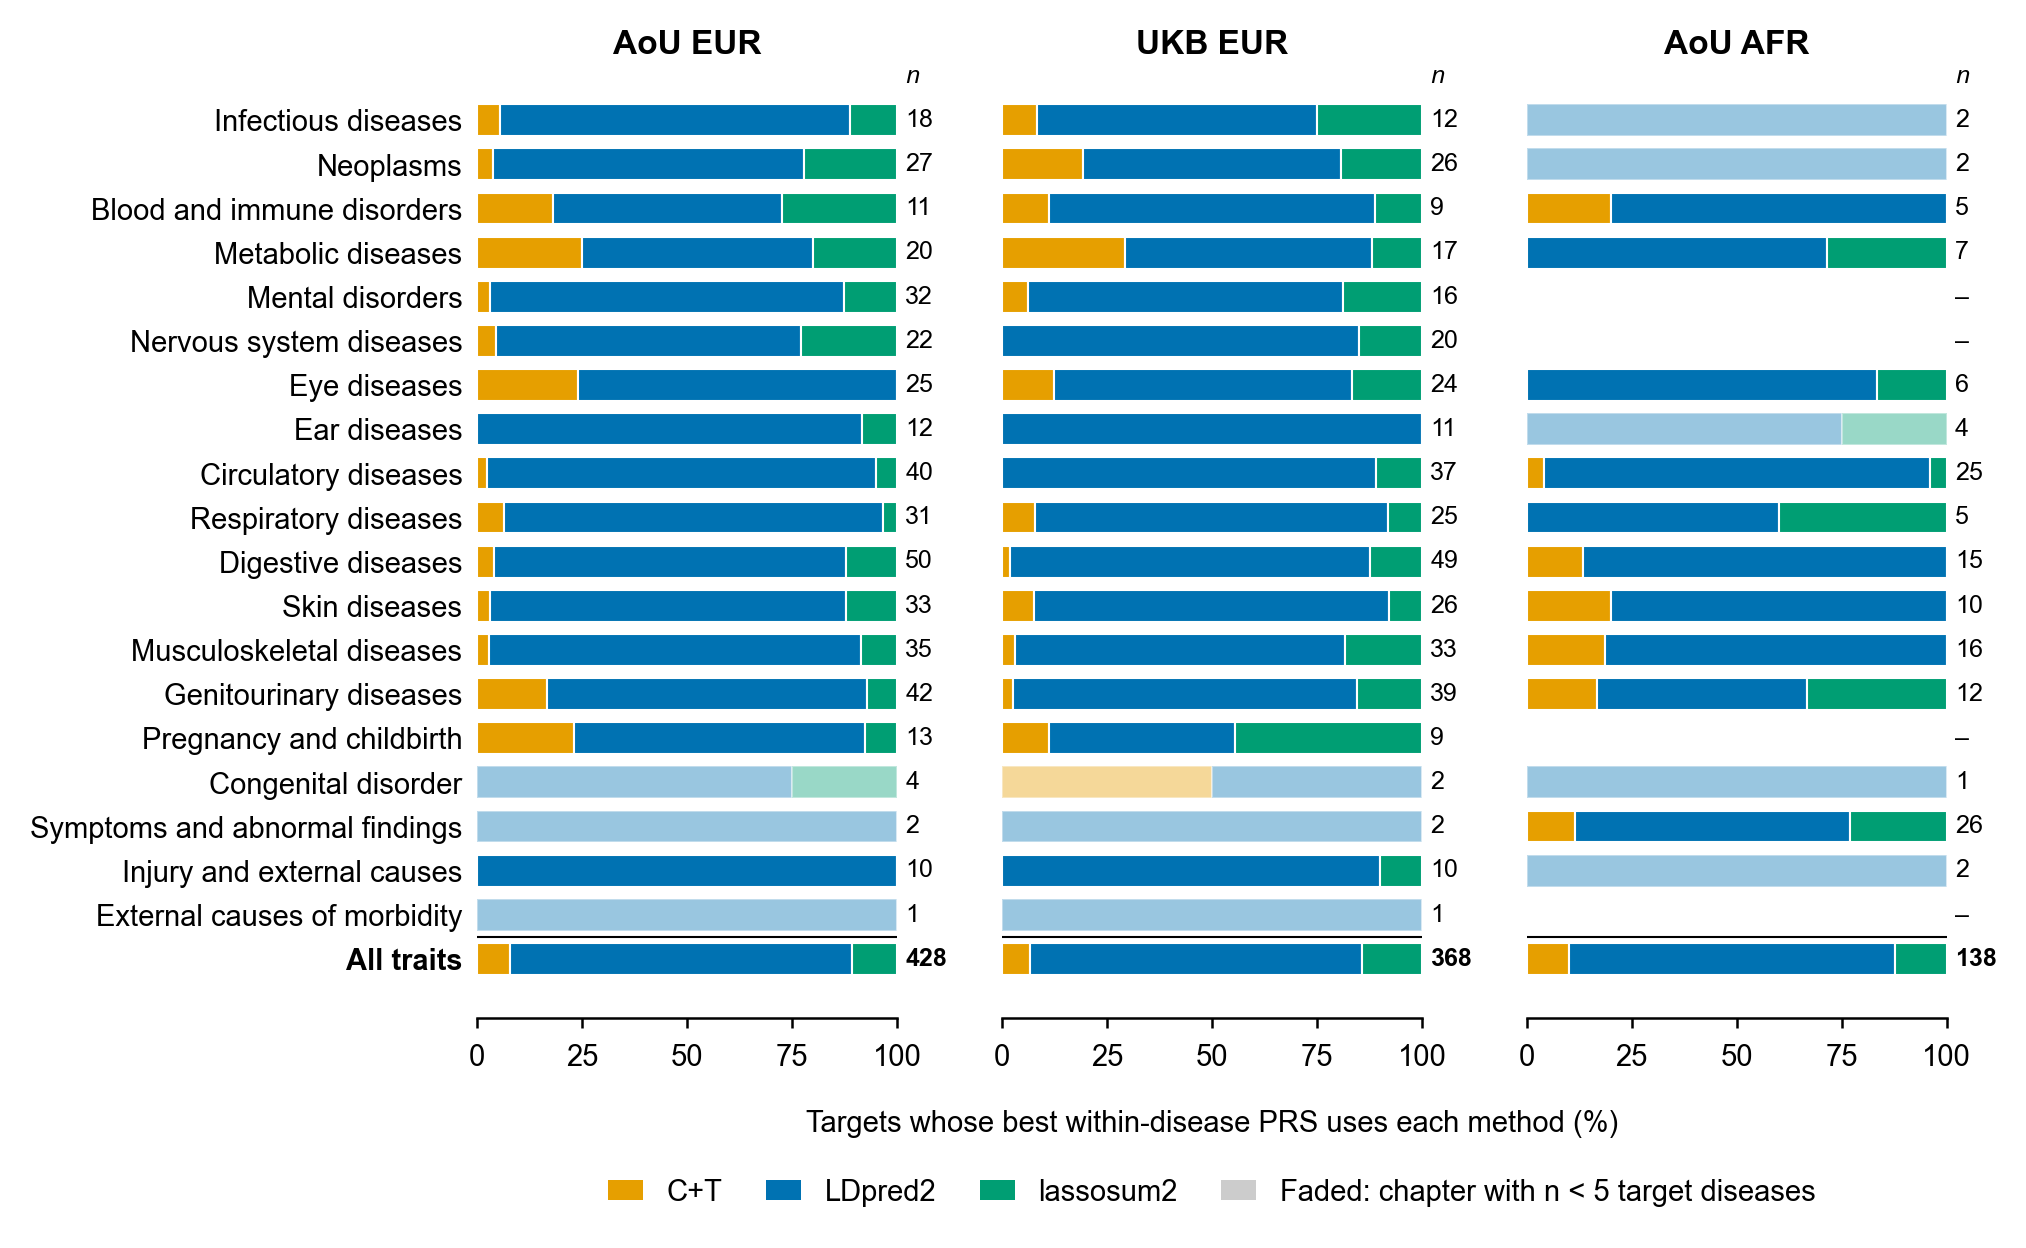

In [6]:
import matplotlib
import matplotlib.pylab as plt
from matplotlib.patches import Patch

### Publication style: Arial 7 pt, thin axes ###
matplotlib.rcParams.update({
    "font.family": "Arial",
    "font.size": 7,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 0,
    "pdf.fonttype": 42,      # editable text in Illustrator
    "svg.fonttype": "none",
    "figure.dpi": 300,       # on-screen / inline rendering resolution
    "savefig.dpi": 600,      # exported raster resolution
})

### PRS methods and colorblind-safe Okabe-Ito colors ###
method_list  = ["C+T", "LDpred2", "lassosum2"]
method_color = {"C+T": "#E69F00", "LDpred2": "#0072B2", "lassosum2": "#009E73"}

### Cohorts to compare (AFR matrix read the same way as AoU/UKB) ###
cohort_list = [
    ("AoU EUR", aou_full_auc_matrix),
    ("UKB EUR", ukb_full_auc_matrix),
    ("AoU AFR", afr_full_auc_matrix),
]

### Build chapter x method count table per cohort (plus an "All traits" row) ###
count_tables = {}
for cohort, auc_mat in cohort_list:

    # Best within-disease method for each target ICD (row)
    best_rows = []
    for icd in auc_mat.index:
        within_cols = [f"{icd}_{m}" for m in method_list if f"{icd}_{m}" in auc_mat.columns]
        within_auc = auc_mat.loc[icd, within_cols].dropna()
        if len(within_auc) == 0:
            continue
        best_rows.append({
            "chapter": cm.assign_chapter(icd),
            "best_method": within_auc.idxmax().rsplit("_", 1)[1],
        })
    best_df = pd.DataFrame(best_rows)
    best_df = best_df[best_df["chapter"].isin(cm.icd_chapters.values())]

    # Counts per chapter (chapter order fixed), then append overall row
    counts = (
        pd.crosstab(best_df["chapter"], best_df["best_method"])
        .reindex(index=list(cm.icd_chapters.values()), columns=method_list, fill_value=0)
    )
    counts.loc["All traits"] = counts.sum(axis=0)
    count_tables[cohort] = counts

### Keep chapters present in at least one cohort; keep "All traits" last ###
chapter_rows = [
    ch for ch in list(cm.icd_chapters.values())
    if any(count_tables[c].loc[ch].sum() > 0 for c, _ in cohort_list)
] + ["All traits"]

### Figure: one panel per cohort, shared y ###
n_panel = len(cohort_list)
fig, axes = plt.subplots(1, n_panel, figsize=(7.1, 4.2), sharey=True, gridspec_kw={"wspace": 0.25})
y_pos = np.arange(len(chapter_rows))
bar_h = 0.72
small_n = 5   # chapters with fewer targets are drawn faded

for ax, (cohort, _) in zip(axes, cohort_list):
    counts = count_tables[cohort].loc[chapter_rows]
    n_row = counts.sum(axis=1)
    prop = counts.div(n_row.replace(0, np.nan), axis=0).fillna(0)

    # Stacked horizontal bars, thin white separators between segments
    left = np.zeros(len(chapter_rows))
    for m in method_list:
        alphas = np.where(n_row.values < small_n, 0.40, 1.0)
        for k in range(len(chapter_rows)):
            ax.barh(
                y_pos[k], prop[m].values[k], left=left[k], height=bar_h,
                color=method_color[m], alpha=alphas[k],
                edgecolor="white", linewidth=0.5,
            )
        left += prop[m].values

    # Per-cohort n at the right end of each bar ("–" if no targets)
    for k, n in enumerate(n_row.values):
        ax.text(1.02, y_pos[k], f"{n}" if n > 0 else "–",
                va="center", ha="left", fontsize=6, clip_on=False,
                fontweight="bold" if chapter_rows[k] == "All traits" else "normal")
    ax.text(1.02, -1.0, "n", va="center", ha="left", fontsize=6, fontstyle="italic", clip_on=False)

    # Separator line above the overall row
    ax.axhline(len(chapter_rows) - 1.5, color="black", linewidth=0.5)

    # Axes formatting
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_xticklabels(["0", "25", "50", "75", "100"])
    ax.set_title(cohort, fontsize=8, fontweight="bold", pad=1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

### Shared y labels on the first panel; top row at the top ###
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(chapter_rows)
axes[0].get_yticklabels()[-1].set_fontweight("bold")
axes[0].invert_yaxis()

### Shared x label (raised to leave room for legend underneath) ###
fig.supxlabel("Targets whose best within-disease PRS uses each method (%)", fontsize=7, x=0.615, y=0.075)

### Legend handles: methods + faded-bar explanation ###
legend_handles = [Patch(facecolor=method_color[m], edgecolor="none", label=m) for m in method_list]
legend_handles.append(Patch(facecolor="grey", alpha=0.40, edgecolor="none", label=f"Faded: chapter with n < {small_n} target diseases"))

# Place legend at the bottom, centered under the panels (panel span 0.27–0.96 -> center 0.615)
fig.legend(handles=legend_handles, loc="lower center", ncol=4, frameon=False,
           bbox_to_anchor=(0.615, 0.0), handlelength=1.2, columnspacing=1.5)

# Shrink top margin (legend gone) and enlarge bottom margin (legend added)
plt.subplots_adjust(left=0.27, right=0.96, top=0.93, bottom=0.17)
plt.show()